# Delete takeoffs and landings
Author: Brian Green (briangre@stanford.edu)

In [1]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import netCDF4 as nc

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()

%matplotlib inline

DZ_THRESH = 500 # (m) the balloon must be within this distance of its cruising altitude after
                #     takeoff and before landing for the data to be included
ALT_THRESH = 10000 # (m) the threshold to determine whether the balloon data has a takeoff or landing

In [2]:
# Load in the data
flights = pd.read_feather('Strateole2_with_ERA5.feather')

# A time delta to fix a timestamping error from earlier (only for the C1 flights)
C1_Timedelta = pd.Timestamp('2019-01-01 00:00:00') - pd.Timestamp('2019-11-01 00:00:00')

C0_01_STR1 2019-11-12 22:25:07.005612
C0_02_STR2 2019-11-12 00:26:34.023701
C0_03_TTL3 2019-11-19 00:22:11.034985
C0_04_TTL1 2019-11-27 23:33:50.095097
C0_05_TTL2 2019-12-05 22:34:53.072681
C0_06_STR1 2019-12-06 02:07:35.087788
C0_07_STR2 2019-12-07 00:30:30.093915
C0_08_STR2 2019-12-07 21:29:28.052409
C1_01_TTL5 2021-10-19 23:24:02
C1_02_STR1 2021-10-20 01:51:40
C1_03_TTL4 2021-10-20 22:56:16
C1_04_STR2 2021-10-21 01:49:31
C1_05_TTL3 2021-10-27 23:29:43
C1_06_TTL5 2021-10-28 22:47:41
C1_07_TTL4 2021-11-01 20:50:52
C1_08_STR1 2021-11-05 00:41:43
C1_09_STR2 2021-11-05 23:47:20
C1_10_TTL3 2021-11-08 20:07:42
C1_11_TTL1 2021-11-08 21:45:11
C1_12_STR4 2021-11-12 01:29:21
C1_13_STR1 2021-11-15 19:58:30


/var/folders/dw/3jtpv5j16bv77dfbt2nw04780000gp/T/ipykernel_36910/1111386483.py:11: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  plt.figure(figsize=(15,4))


C1_15_TTL4 2021-11-22 20:04:58
C1_16_TTL5 2021-11-22 22:01:08
C1_17_TTL3 2021-11-26 00:01:36


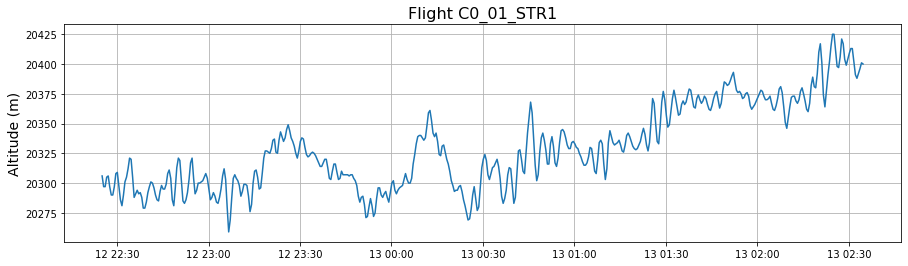

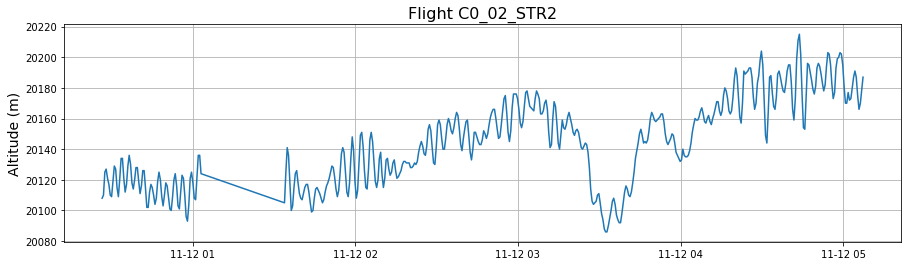

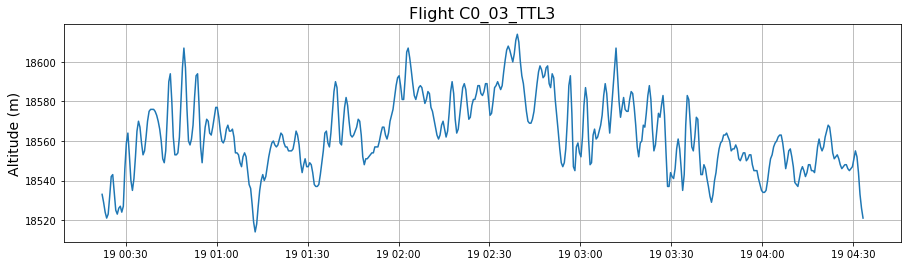

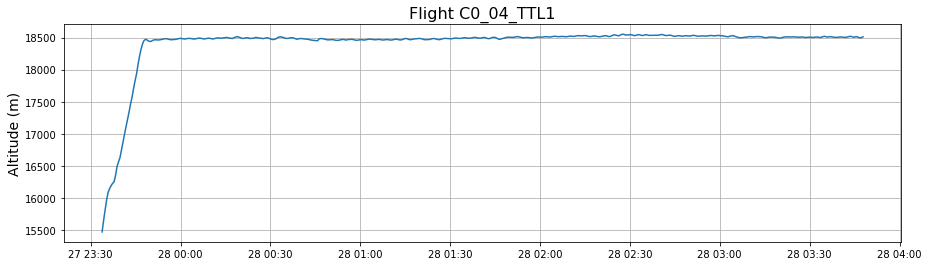

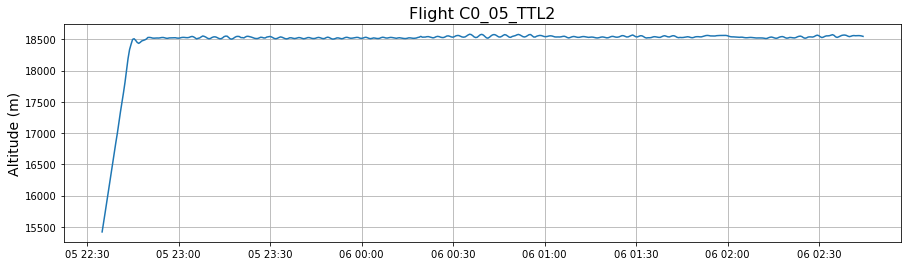

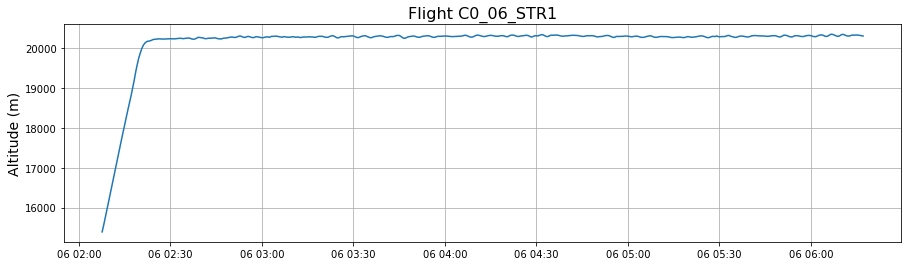

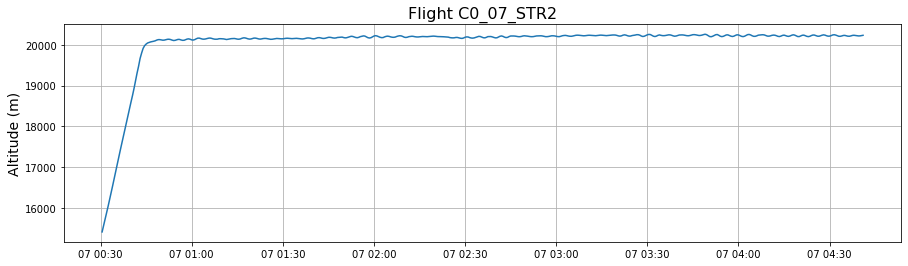

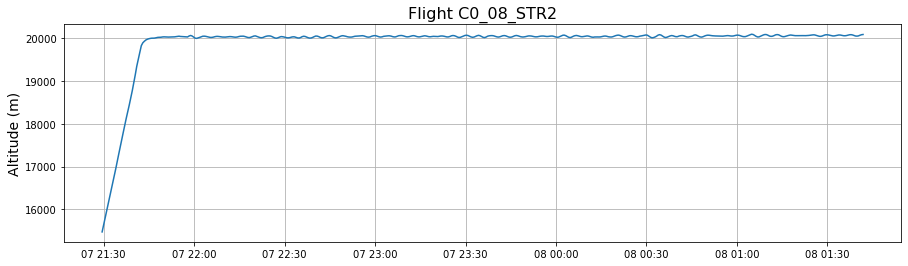

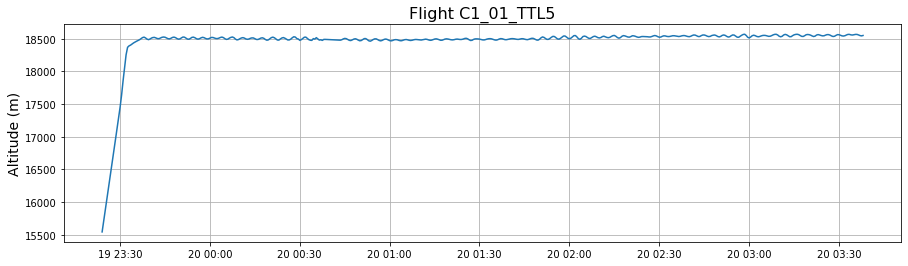

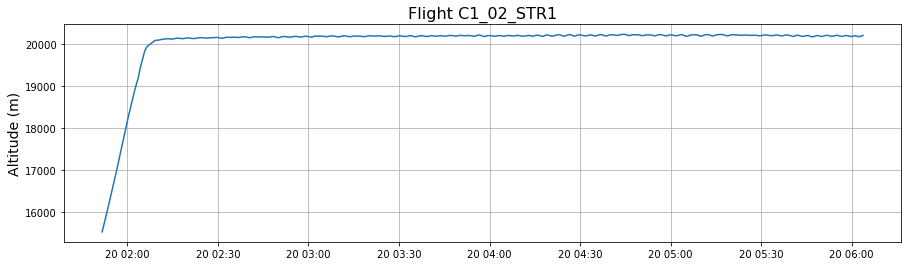

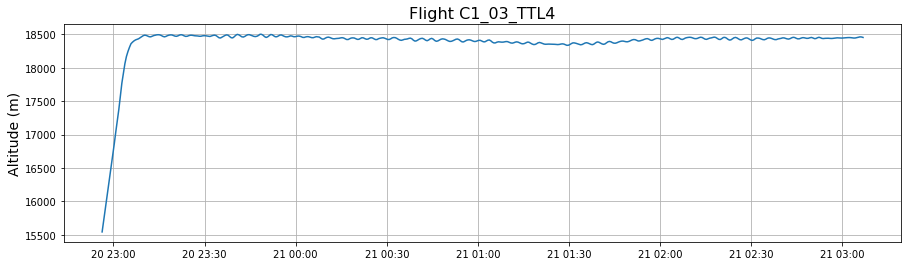

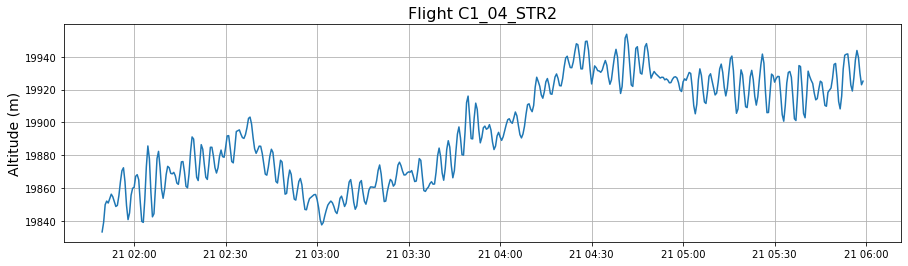

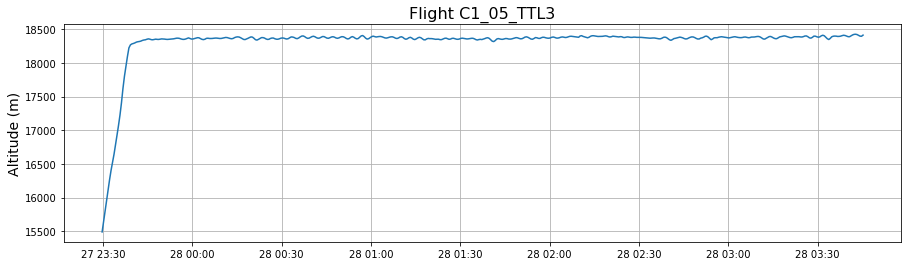

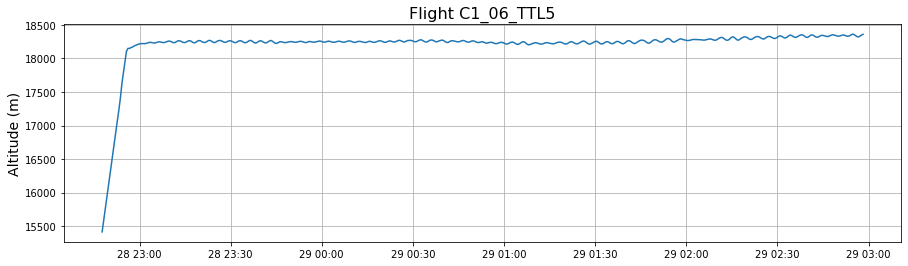

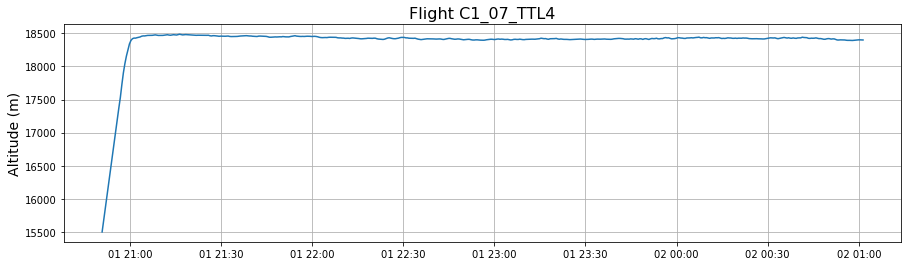

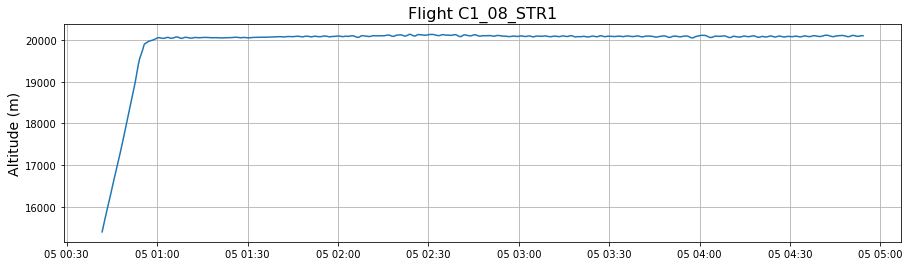

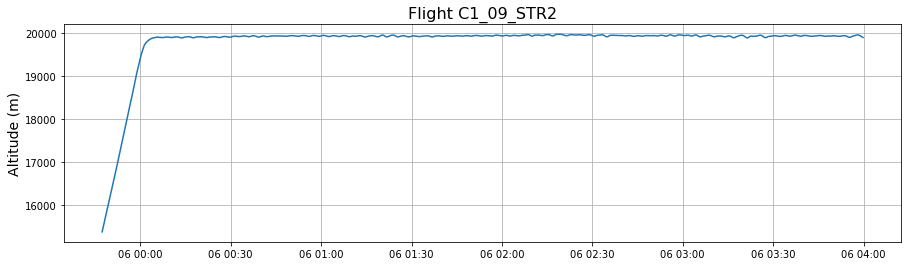

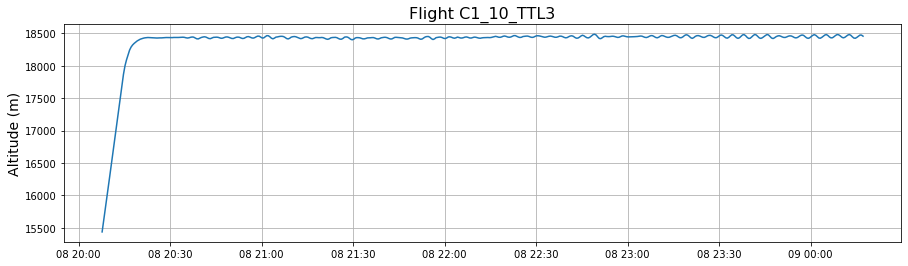

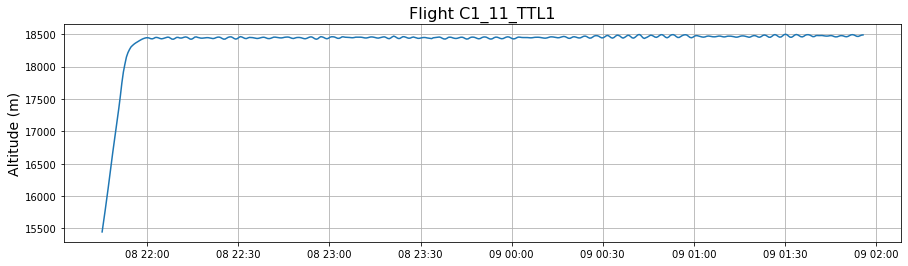

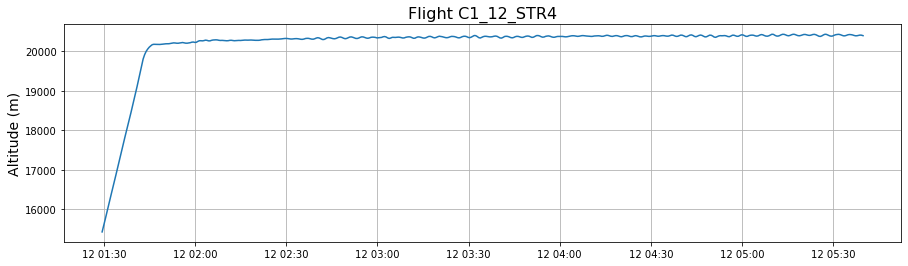

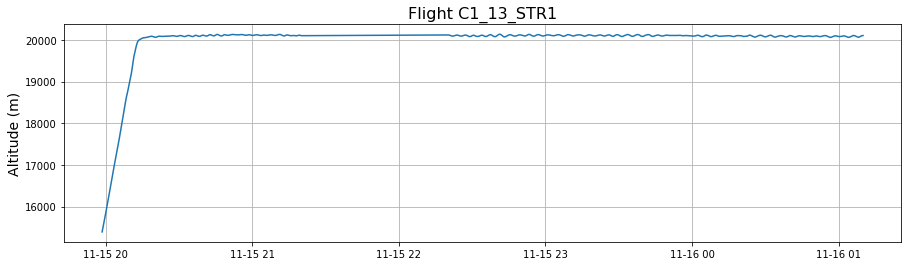

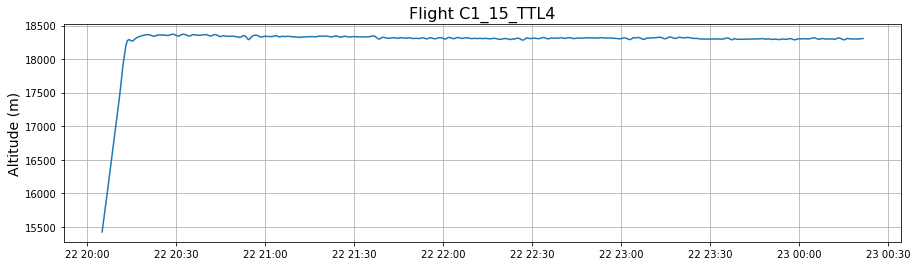

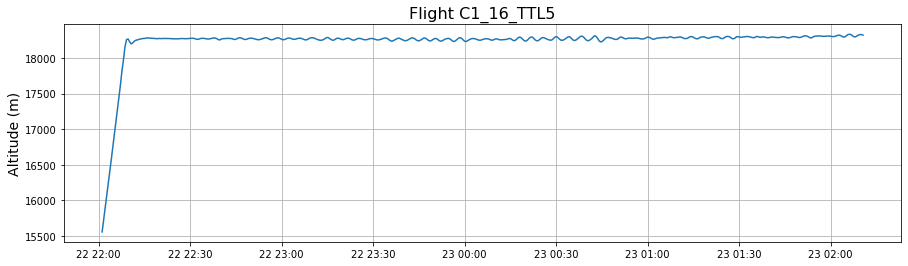

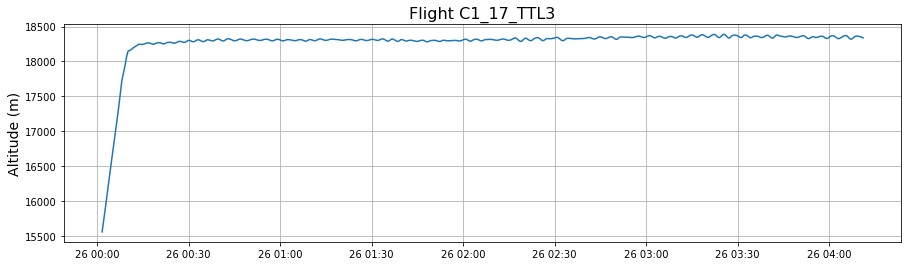

In [3]:
# Plot the beginning of each flight
flight_ids = flights.flight_id.unique()
n_flights = flight_ids.size

for i in np.arange(n_flights):
    
    flight = flights[flights.flight_id == flight_ids[i]].copy()
    print(flight_ids[i], flight.time.iloc[0])
    ind_start = 0
    
    plt.figure(figsize=(15,4))
    plt.plot(flight.time[ind_start:ind_start+500],flight.altitude[ind_start:ind_start+500])
    plt.grid()
    plt.title(f'Flight {flight_ids[i]}', fontsize=16)
    plt.ylabel('Altitude (m)', fontsize=14);
    
start_time = np.array([pd.Timestamp('2019-11-12 22:25:07'),
                       pd.Timestamp('2019-11-12 00:25:34'),
                       pd.Timestamp('2019-11-19 00:21:11'),
                       pd.Timestamp('2019-11-27 23:50:00'),
                       pd.Timestamp('2019-12-05 22:50:00'),
                       pd.Timestamp('2019-12-06 02:25:00'),
                       pd.Timestamp('2019-12-07 00:50:00'),
                       pd.Timestamp('2019-12-07 21:45:00'),
                       pd.Timestamp('2022-08-19 23:40:00') + C1_Timedelta,
                       pd.Timestamp('2022-08-20 02:15:00') + C1_Timedelta,
                       pd.Timestamp('2022-08-20 23:10:00') + C1_Timedelta,
                       pd.Timestamp('2022-08-21 01:55:00') + C1_Timedelta,
                       pd.Timestamp('2022-08-27 23:40:00') + C1_Timedelta,
                       pd.Timestamp('2022-08-28 23:00:00') + C1_Timedelta,
                       pd.Timestamp('2022-09-01 21:05:00') + C1_Timedelta,
                       pd.Timestamp('2022-09-05 01:00:00') + C1_Timedelta,
                       pd.Timestamp('2022-09-06 00:10:00') + C1_Timedelta,
                       pd.Timestamp('2022-09-08 20:25:00') + C1_Timedelta,
                       pd.Timestamp('2022-09-08 22:00:00') + C1_Timedelta,
                       pd.Timestamp('2022-09-12 01:50:00') + C1_Timedelta,
                       pd.Timestamp('2022-09-15 20:20:00') + C1_Timedelta,
                       pd.Timestamp('2022-09-22 20:20:00') + C1_Timedelta,
                       pd.Timestamp('2022-09-22 22:15:00') + C1_Timedelta,
                       pd.Timestamp('2022-09-26 00:15:00') + C1_Timedelta])

# Trim off any takeoffs
flights_no_takeoffs = pd.DataFrame(columns = flights.columns)
for i in np.arange(n_flights):
    flight = flights[flights.flight_id == flight_ids[i]].copy()
    flight = flight[flight.time >= start_time[i]]
    flights_no_takeoffs = flights_no_takeoffs.append(flight, ignore_index=True)

C0_01_STR1 2020-02-27 23:17:37.007114001
C0_02_STR2 2020-02-23 02:03:22.013200
C0_03_TTL3 2020-02-28 09:19:11.077482
C0_04_TTL1 2020-02-02 11:35:50.082497
C0_05_TTL2 2020-02-23 21:08:42.002397999
C0_06_STR1 2020-02-01 17:31:06.003289
C0_07_STR2 2020-02-28 04:39:00.091216
C0_08_STR2 2020-02-22 23:20:18.082079999
C1_01_TTL5 2021-10-21 04:53:02
C1_02_STR1 2021-11-01 12:03:13
C1_03_TTL4 2021-11-21 07:05:43
C1_04_STR2 2021-11-19 19:46:31
C1_05_TTL3 2021-12-17 06:03:38
C1_06_TTL5 2021-12-11 12:11:41
C1_07_TTL4 2021-12-16 04:58:52
C1_08_STR1 2021-12-29 00:15:43
C1_09_STR2 2022-01-12 12:17:50
C1_10_TTL3 2021-12-16 23:23:42
C1_11_TTL1 2021-12-15 16:21:11
C1_12_STR4 2022-01-02 11:23:51
C1_13_STR1 2022-01-25 22:25:00


/var/folders/dw/3jtpv5j16bv77dfbt2nw04780000gp/T/ipykernel_36910/273216952.py:10: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  plt.figure(figsize=(15,4))


C1_15_TTL4 2022-01-18 06:29:36
C1_16_TTL5 2021-12-19 07:31:08
C1_17_TTL3 2021-12-16 12:33:57


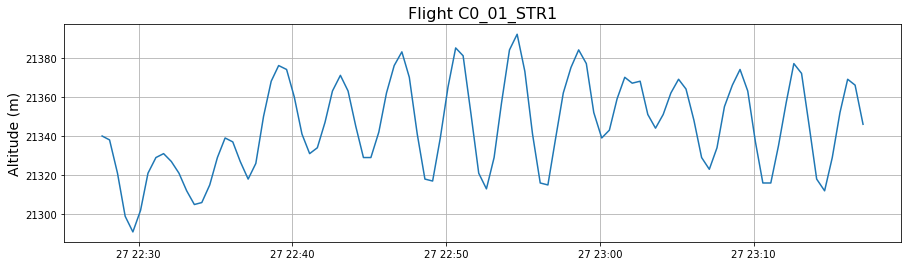

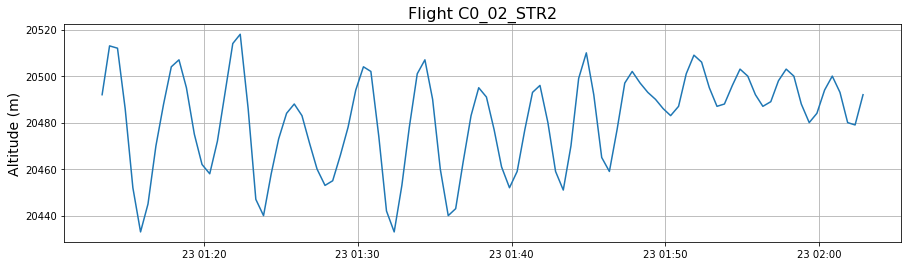

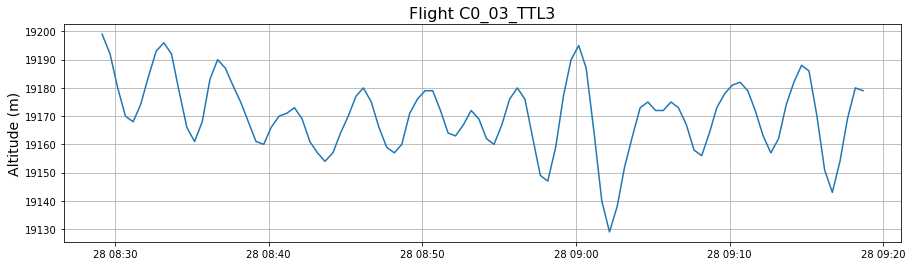

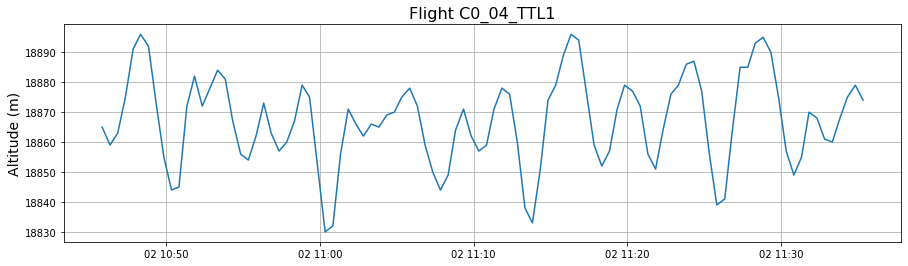

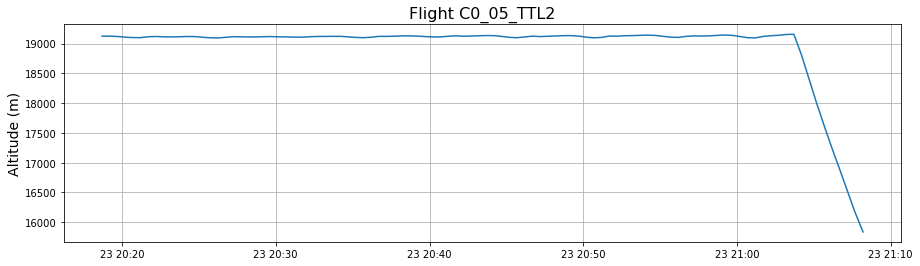

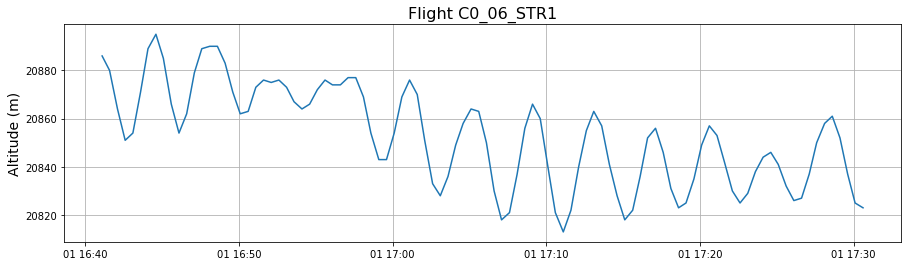

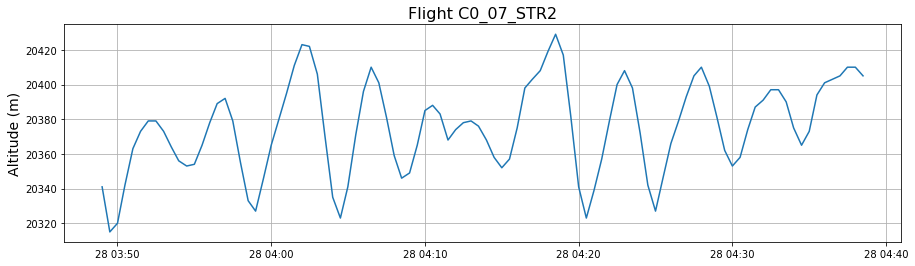

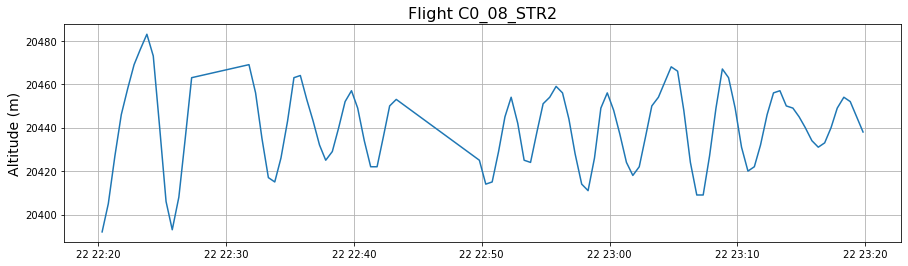

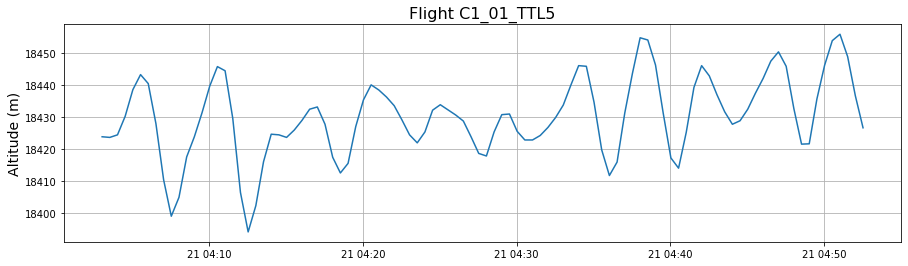

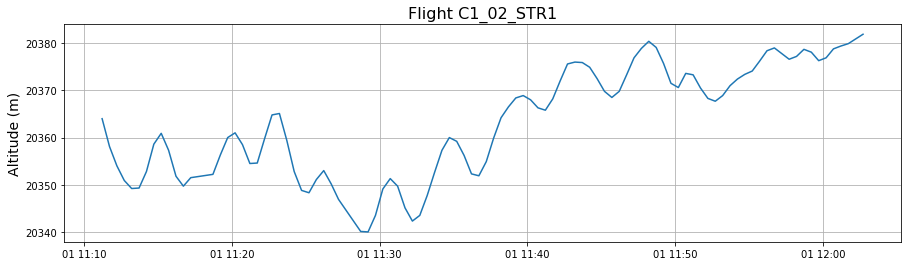

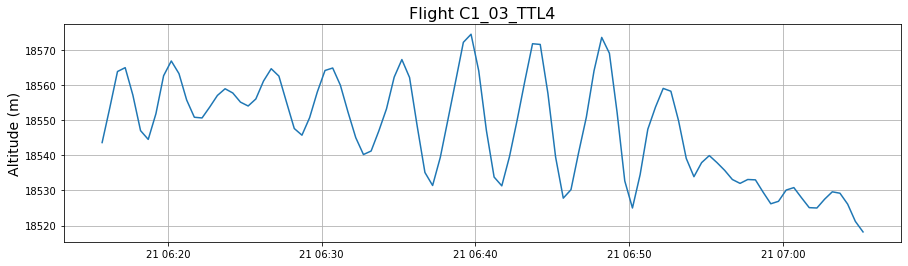

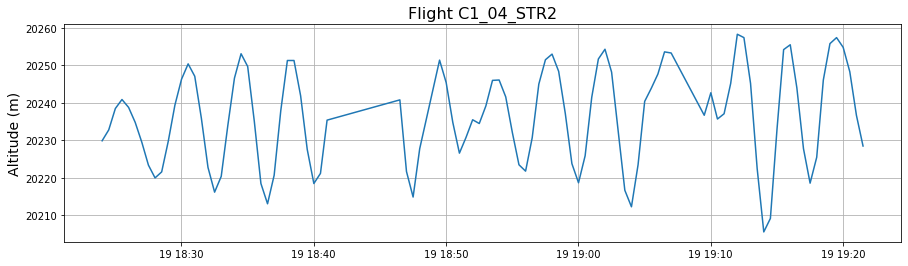

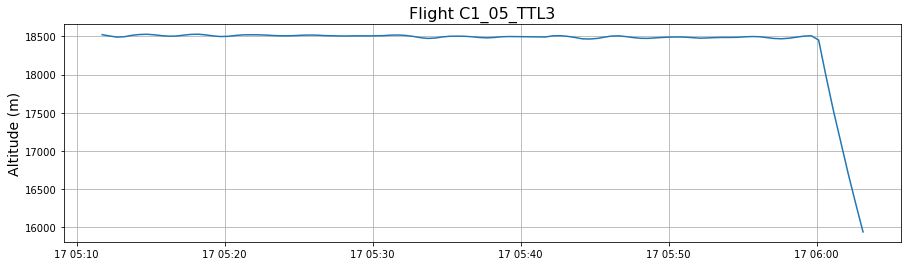

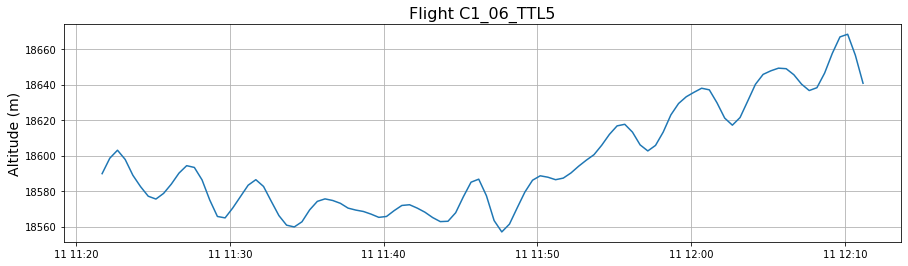

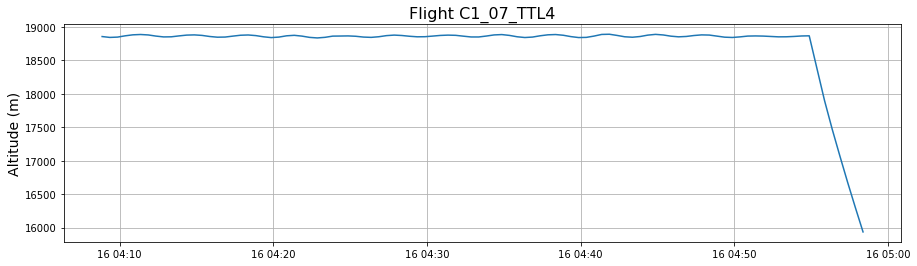

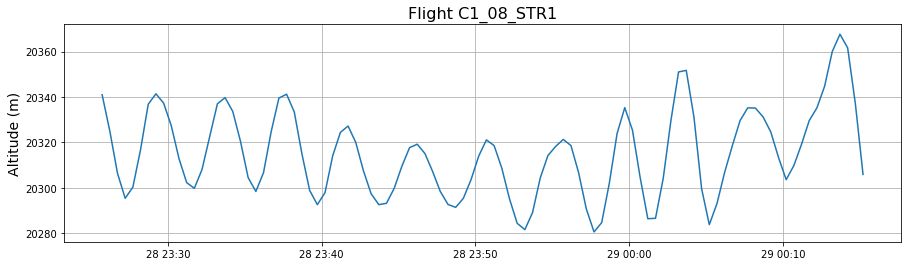

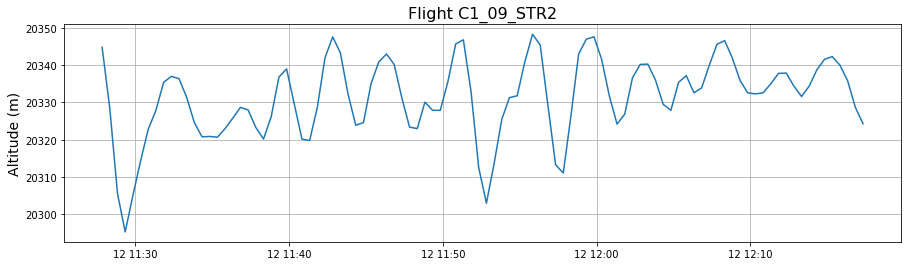

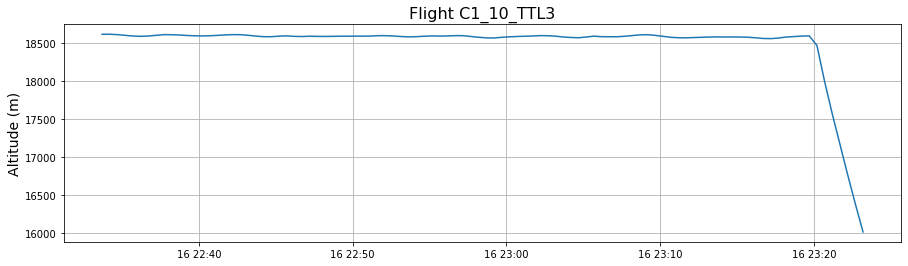

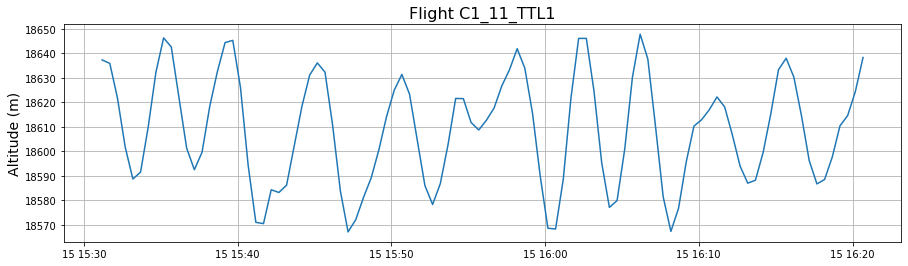

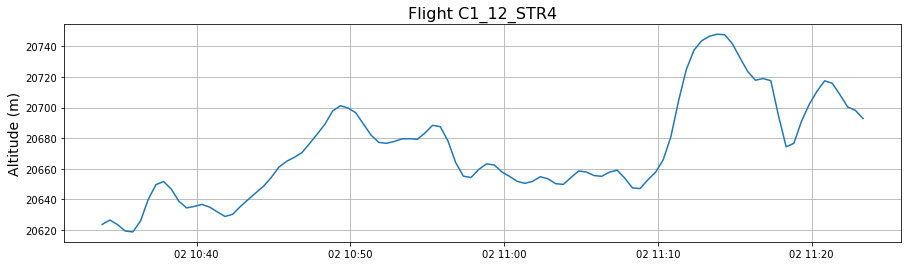

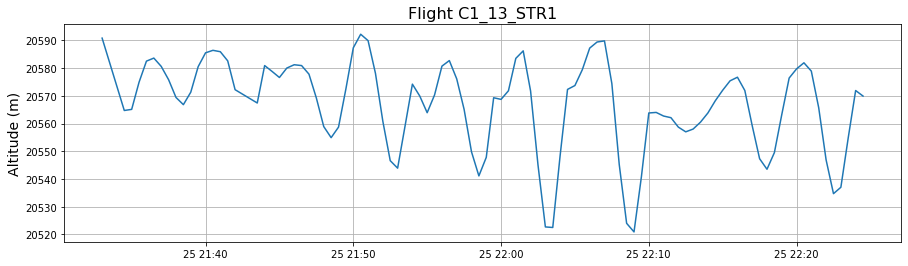

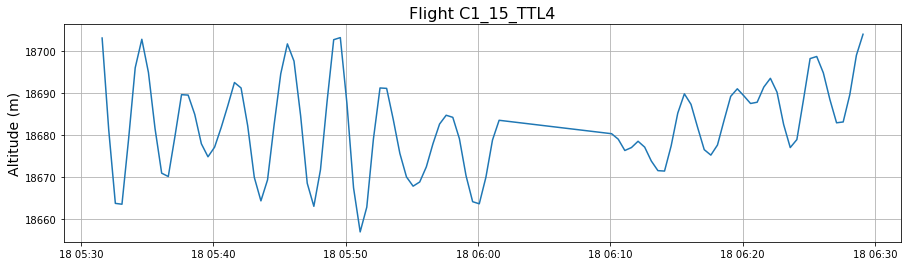

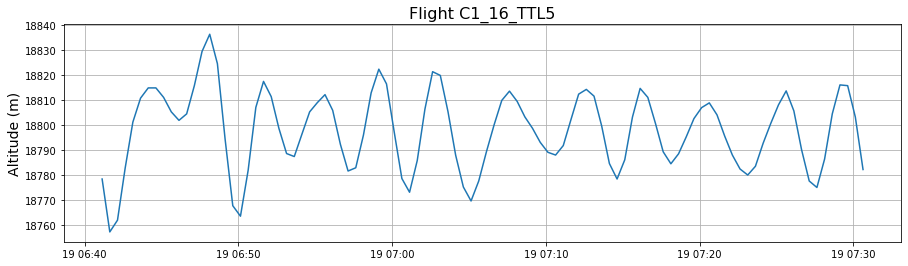

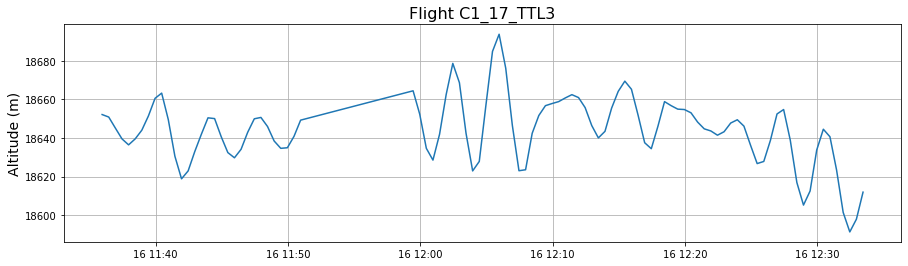

In [4]:
# Plot the ending of each flight
for i in np.arange(n_flights):
    
    flight = flights[flights.flight_id == flight_ids[i]].copy()
    print(flight_ids[i], flight.time.iloc[-1])
    ind_stop = -1
    if flight_ids[i] == 'C1_04_STR2':
        ind_stop = -50
    
    plt.figure(figsize=(15,4))
    plt.plot(flight.time[ind_stop-100:ind_stop],flight.altitude[ind_stop-100:ind_stop])
    plt.grid()
    plt.title(f'Flight {flight_ids[i]}', fontsize=16)
    plt.ylabel('Altitude (m)', fontsize=14);
    
stop_time = np.array([pd.Timestamp('2020-02-27 23:17:38'),
                      pd.Timestamp('2020-02-23 02:04:22'),
                      pd.Timestamp('2020-02-28 09:20:11'),
                      pd.Timestamp('2020-02-02 11:36:50'),
                      pd.Timestamp('2020-02-23 21:00:00'),
                      pd.Timestamp('2020-02-01 17:32:06'),
                      pd.Timestamp('2020-02-28 04:40:00'),
                      pd.Timestamp('2020-02-22 23:21:18'),
                      pd.Timestamp('2022-08-21 04:54:02') + C1_Timedelta,
                      pd.Timestamp('2022-09-01 12:04:13') + C1_Timedelta,
                      pd.Timestamp('2022-09-21 07:06:43') + C1_Timedelta,
                      pd.Timestamp('2022-09-19 19:35:00') + C1_Timedelta,
                      pd.Timestamp('2022-10-17 05:55:00') + C1_Timedelta,
                      pd.Timestamp('2022-10-11 12:12:41') + C1_Timedelta,
                      pd.Timestamp('2022-10-16 04:50:00') + C1_Timedelta,
                      pd.Timestamp('2022-10-29 00:15:43') + C1_Timedelta,
                      pd.Timestamp('2022-11-12 12:18:50') + C1_Timedelta,
                      pd.Timestamp('2022-10-16 23:15:00') + C1_Timedelta,
                      pd.Timestamp('2022-10-15 16:22:11') + C1_Timedelta,
                      pd.Timestamp('2022-11-02 11:24:51') + C1_Timedelta,
                      pd.Timestamp('2022-11-25 22:26:00') + C1_Timedelta,
                      pd.Timestamp('2022-11-18 06:30:36') + C1_Timedelta,
                      pd.Timestamp('2022-10-19 07:32:08') + C1_Timedelta,
                      pd.Timestamp('2022-10-16 12:34:57') + C1_Timedelta])

# Trim off any landings
flights_no_takeoffs_or_landings = pd.DataFrame(columns = flights.columns)
for i in np.arange(n_flights):
    flight = flights_no_takeoffs[flights_no_takeoffs.flight_id == flight_ids[i]].copy()
    flight = flight[flight.time <= stop_time[i]]
    flights_no_takeoffs_or_landings = flights_no_takeoffs_or_landings.append(flight, ignore_index=True)

/var/folders/dw/3jtpv5j16bv77dfbt2nw04780000gp/T/ipykernel_36910/1364992482.py:7: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  plt.figure(figsize=(15,4))


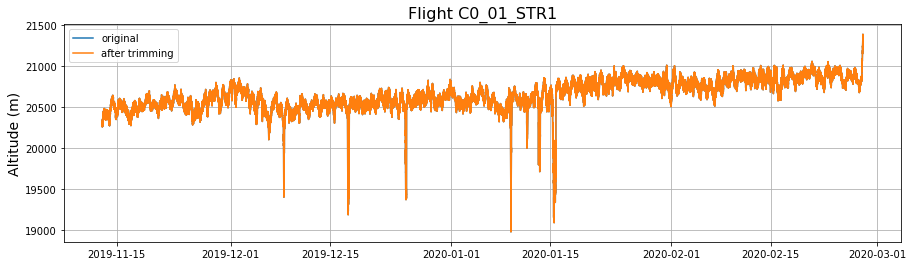

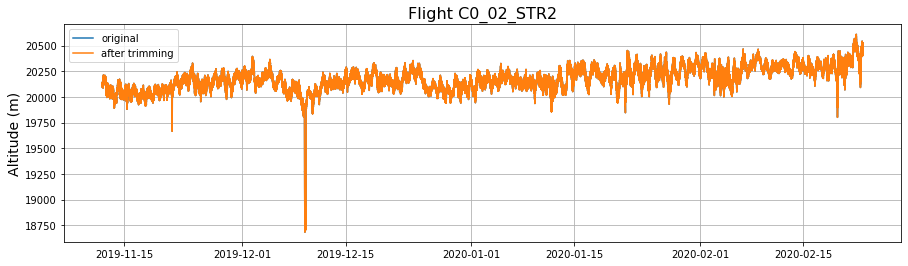

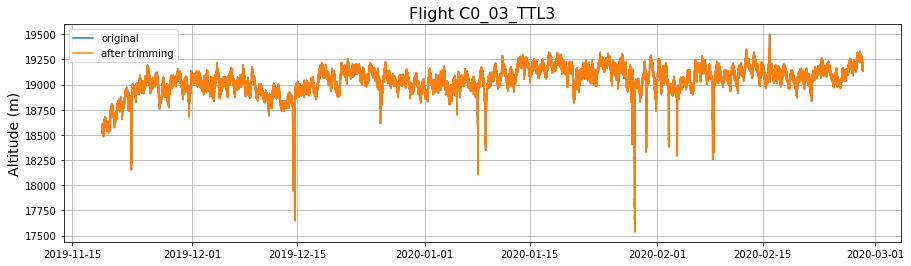

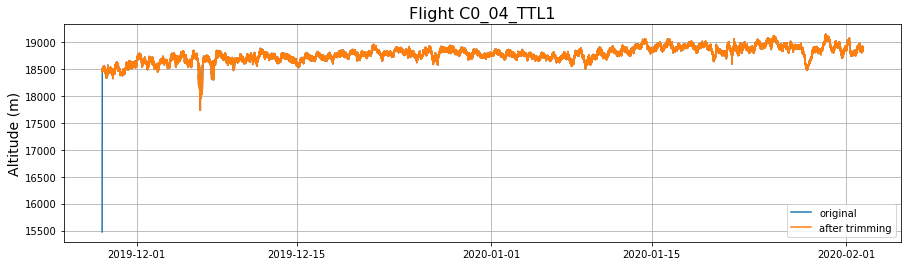

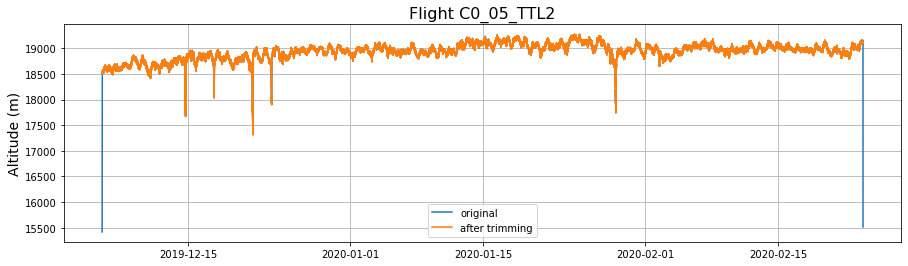

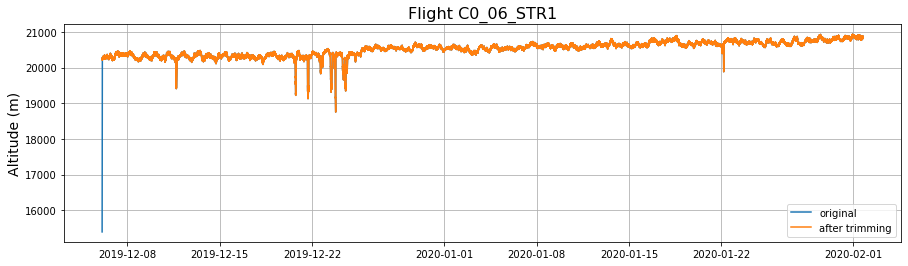

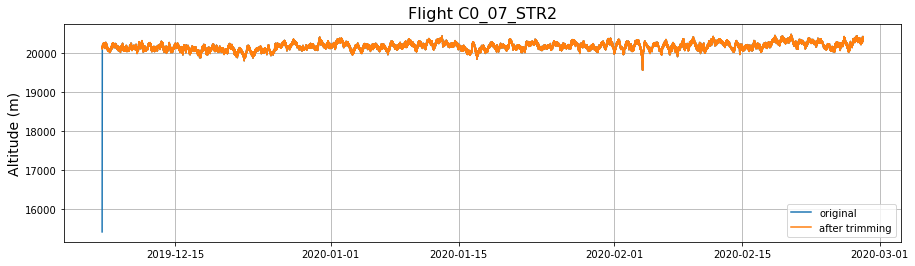

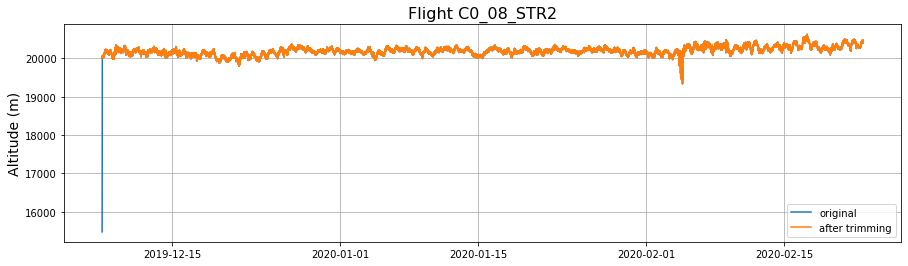

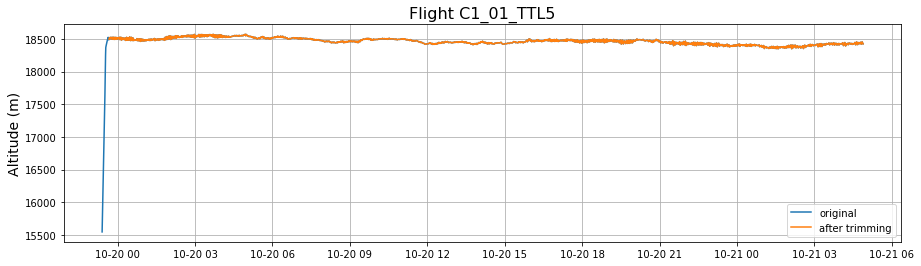

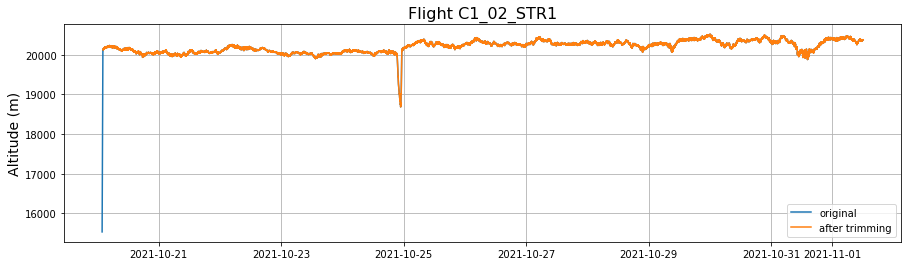

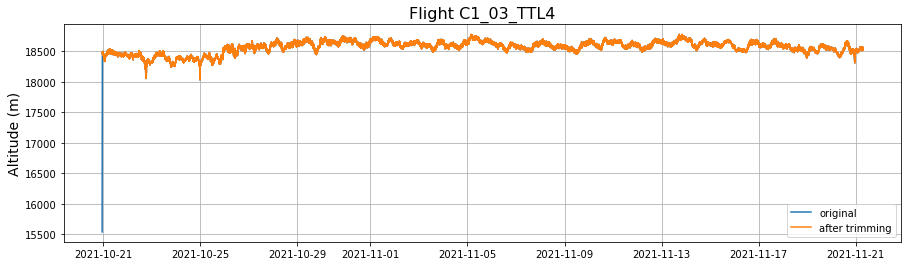

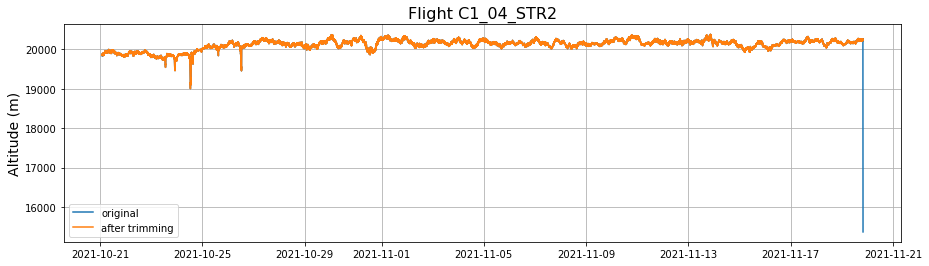

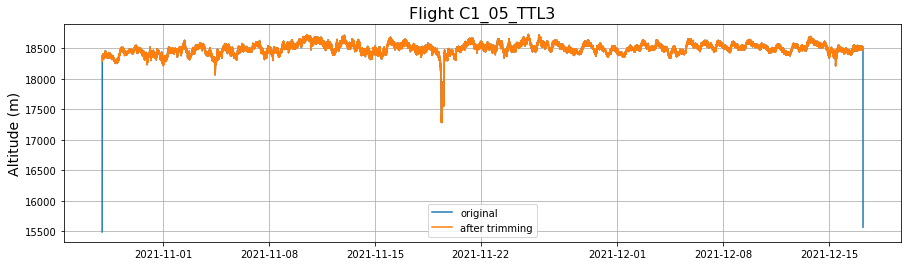

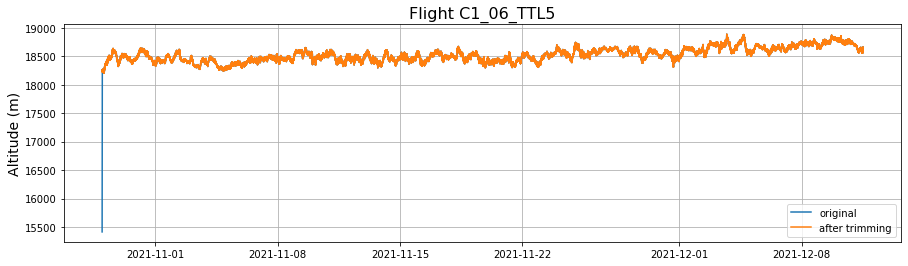

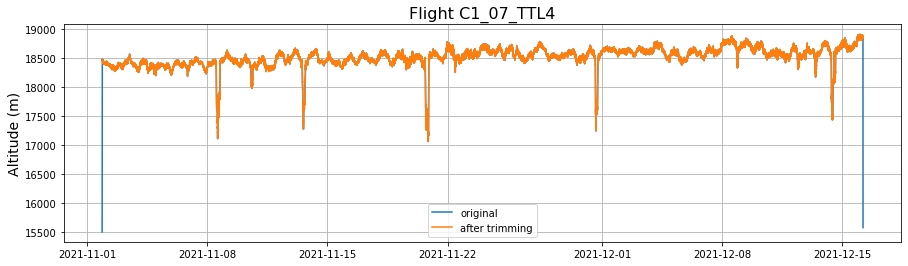

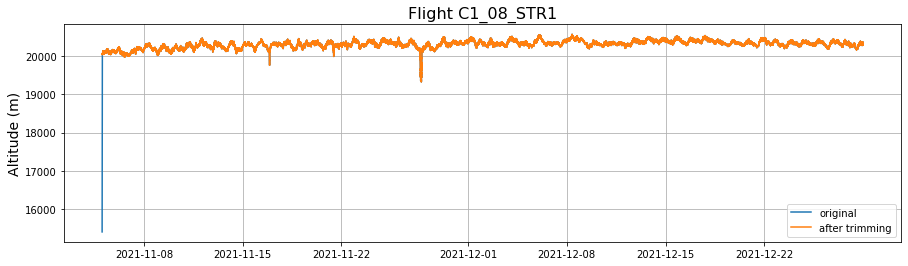

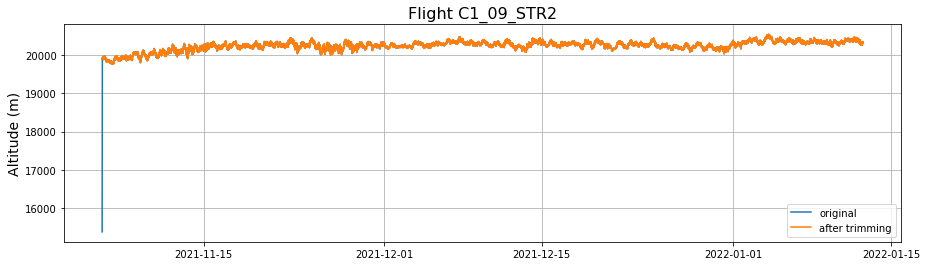

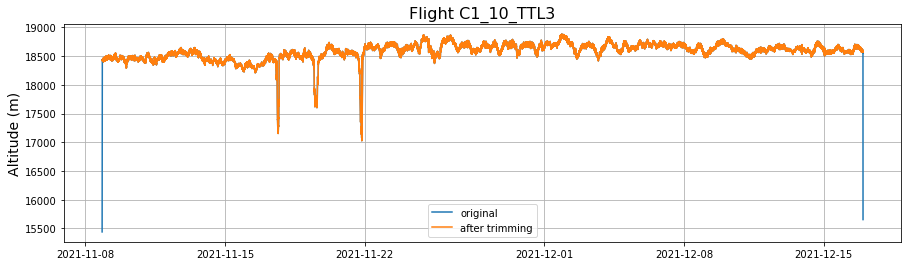

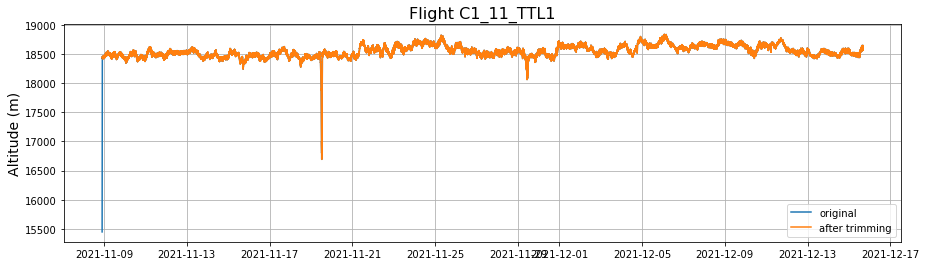

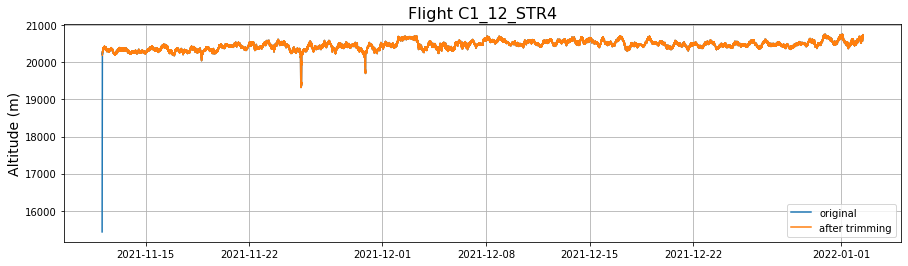

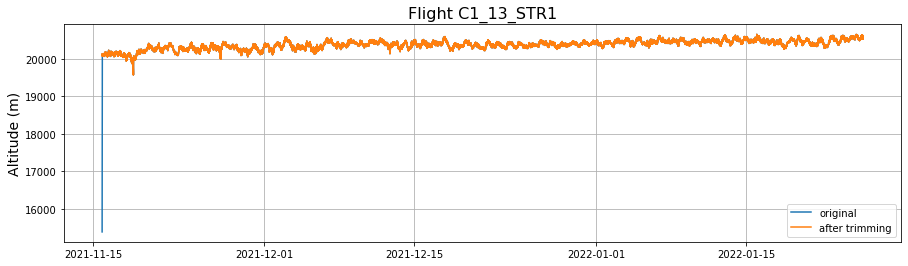

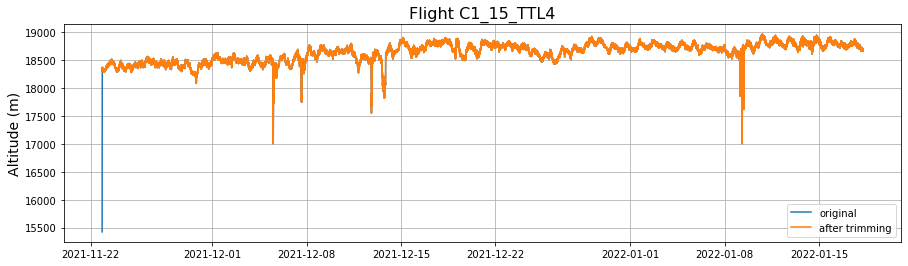

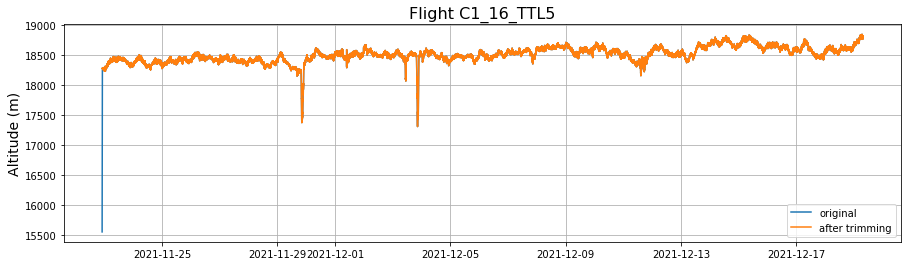

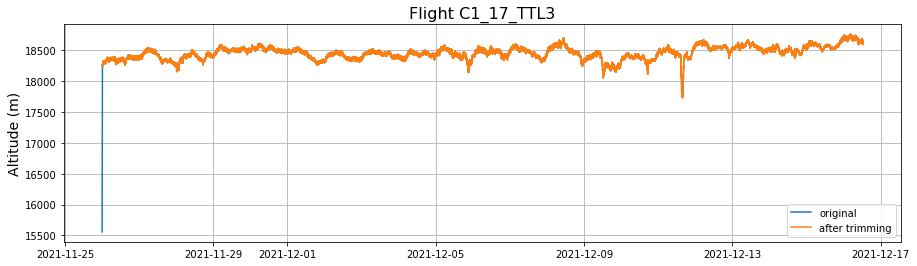

In [5]:
# Plot the before and after
for i in np.arange(n_flights):
    
    flight1 = flights[flights.flight_id == flight_ids[i]].copy()
    flight2 = flights_no_takeoffs_or_landings[flights_no_takeoffs_or_landings.flight_id == flight_ids[i]].copy()
    
    plt.figure(figsize=(15,4))
    plt.plot(flight1.time,flight1.altitude)
    plt.plot(flight2.time,flight2.altitude)
    plt.grid()
    plt.title(f'Flight {flight_ids[i]}', fontsize=16)
    plt.ylabel('Altitude (m)', fontsize=14)
    plt.legend(['original','after trimming']);

In [6]:
# Save the data
flights_no_takeoffs_or_landings.to_feather('Strateole2_with_ERA5_2_takeoffs_landings.feather') 
flights_no_takeoffs_or_landings

,flight_id,time,latitude,longitude,altitude,u,v,pressure,T_ERA5,N2_ERA5,superpressure
0,C0_01_STR1,2019-11-12 22:25:07.005612,-4.834385,55.593623,20306.0,NaN,NaN,53.838274,203.456487,0.000691,8.270000
1,C0_01_STR1,2019-11-12 22:25:37.076783,-4.836663,55.593735,20297.0,0.361103,-8.387708,53.902477,203.428319,0.000691,8.270000
2,C0_01_STR1,2019-11-12 22:26:07.026208,-4.838898,55.593818,20297.0,0.256162,-8.362772,53.893533,203.432243,0.000691,8.200000
3,C0_01_STR1,2019-11-12 22:26:37.098505,-4.841163,55.593873,20305.0,0.200608,-8.576493,53.804733,203.471199,0.000691,8.200000
4,C0_01_STR1,2019-11-12 22:27:07.047890,-4.843513,55.593927,20306.0,0.188386,-8.961514,53.773176,203.485038,0.000691,8.770000
...,...,...,...,...,...,...,...,...,...,...,...
3762539,C1_17_TTL3,2021-12-16 12:31:57.000000,-2.211255,125.868032,18601.4,-3.421231,2.695646,71.513419,191.921589,0.000809,10.187500
3762540,C1_17_TTL3,2021-12-16 12:32:27.000000,-2.210570,125.867093,18591.3,-3.461483,2.463263,71.650113,191.897698,0.000808,9.933594
3762541,C1_17_TTL3,2021-12-16 12:32:57.000000,-2.209930,125.866168,18597.9,-3.272620,2.364113,71.578122,191.910271,0.000809,9.821289
3762542,C1_17_TTL3,2021-12-16 12:33:27.000000,-2.209298,125.865332,18611.9,-2.845354,2.463263,71.404752,191.940639,0.000809,9.756836
